# 🚨 Praktická laboratoř: Local Outlier Factor (LOF) v Scikit-learn

> **Kontext kurzu:** *Local_Outlier_Factor_-_sample_implementation.pdf* & *Anomaly_detection_-_introduction.pdf*
>
> Tento sešit provádí kompletní praktickou implementaci detekce anomálií:
> 1. **Vzorová implementace ze slajdů 15–19:** `make_blobs(n_samples=500, centers=2, cluster_std=2.0)`, `contamination=0.10` a přesná reprodukce červených odlehlých bodů.
> 2. **Ruční výpočetní příklad ze slajdů 9–13:** Krok za krokem výpočet $RD$, $LRD$ a $LOF$ pro 5 bodů.
> 3. **Dataset kurzu `blobs_dataset.csv` (1 000 bodů):** Aplikace LOF a bublinový graf skóre anomality.
> 4. **Srovnání metod:** Porovnání LOF s algoritmem **Isolation Forest**.
> 5. **Varying Density experiment:** Důkaz, proč LOF triumfuje nad globální vzdáleností při různé hustotě shluků.
> 6. **Režim Novelty Detection (`novelty=True`):** Inherence na nových příchozích datech.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.preprocessing import StandardScaler

# Nastavení vizuálního stylu
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
print('Knihovny úspěšně načteny.')

Knihovny úspěšně načteny.


## 1. Vzorová implementace ze slajdů 15–20

Podle slajdů kurzu vytvoříme 500 vzorků ve 2 centrech přes `make_blobs`, natrénujeme `LocalOutlierFactor(n_neighbors=20, contamination=0.1)` a vykreslíme anomálie v červené barvě pomocí maticového indexování `marker_colors[(y_pred + 1) // 2]`.

Normální pozorování (Inliers, modrá): 450
Anomálie (Outliers, červená): 50 (přesně 10 % dle contamination=0.10)
Rozsah negative_outlier_factor_: min = -2.6992, max = -0.9542


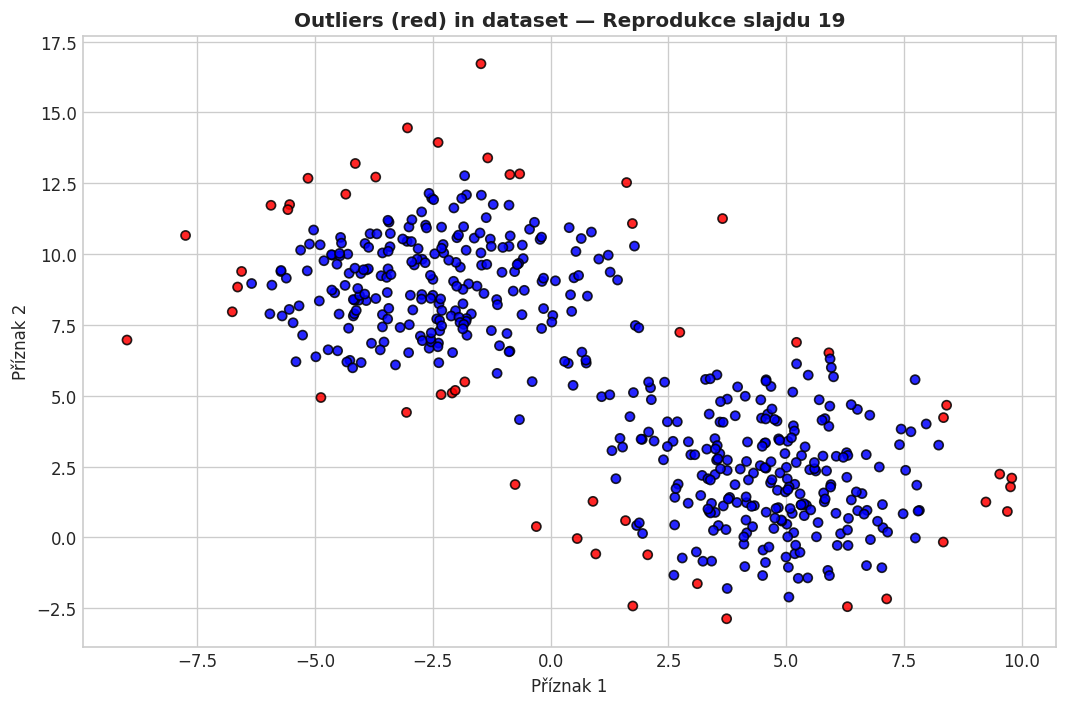

In [2]:
# 1. Generování datasetu o 500 bodech (slajd 15)
X_slide, labels_slide = make_blobs(n_samples=500, centers=2, random_state=42, cluster_std=2.0)

# 2. Vytvoření instance modelu LOF (slajd 16)
lof_slide = LocalOutlierFactor(n_neighbors=20, contamination=0.1)

# 3. Fitování a predikce (slajd 17)
y_pred_slide = lof_slide.fit_predict(X_slide)

# 4. Získání skóre (slajd 18)
lof_scores_slide = lof_slide.negative_outlier_factor_

n_anomalies = int(np.sum(y_pred_slide == -1))
n_normal = int(np.sum(y_pred_slide == 1))
print(f'Normální pozorování (Inliers, modrá): {n_normal}')
print(f'Anomálie (Outliers, červená): {n_anomalies} (přesně {n_anomalies/len(X_slide)*100:.0f} % dle contamination=0.10)')
print(f'Rozsah negative_outlier_factor_: min = {lof_scores_slide.min():.4f}, max = {lof_scores_slide.max():.4f}')

# 5. Generování grafu přesně dle slajdu 19
plt.figure(figsize=(9, 6))
marker_colors = np.array(['r', 'b'])
plt.scatter(X_slide[:, 0], X_slide[:, 1], s=30, color=marker_colors[(y_pred_slide + 1) // 2], edgecolors='k', alpha=0.85)
plt.title('Outliers (red) in dataset — Reprodukce slajdu 19', fontsize=12, fontweight='bold')
plt.xlabel('Příznak 1')
plt.ylabel('Příznak 2')
plt.tight_layout()
plt.show()

## 2. Ruční výpočet na 5 bodech ze slajdů 9–13

Ověříme přesný matematický aparát výpočtu dosahové vzdálenosti ($RD$), dosahové hustoty ($LRD$) a finálního poměru $LOF$ pro $k = 2$.

Krokový ruční výpočet ze slajdů kurzu:
Bod   X   Y  k_dist (k=2)    LRD  LOF      Hodnocení
 X1 0.0 0.0           2.0 0.5000  1.0   Normální bod
 X2 2.0 0.0           2.0 0.5000  1.0   Normální bod
 X3 0.0 2.0           2.0 0.5000  1.0   Normální bod
 X4 3.0 2.0           3.0 0.3333  1.5 Mírná anomálie
 X5 6.0 0.0           6.0 0.1667  2.5 Silná anomálie


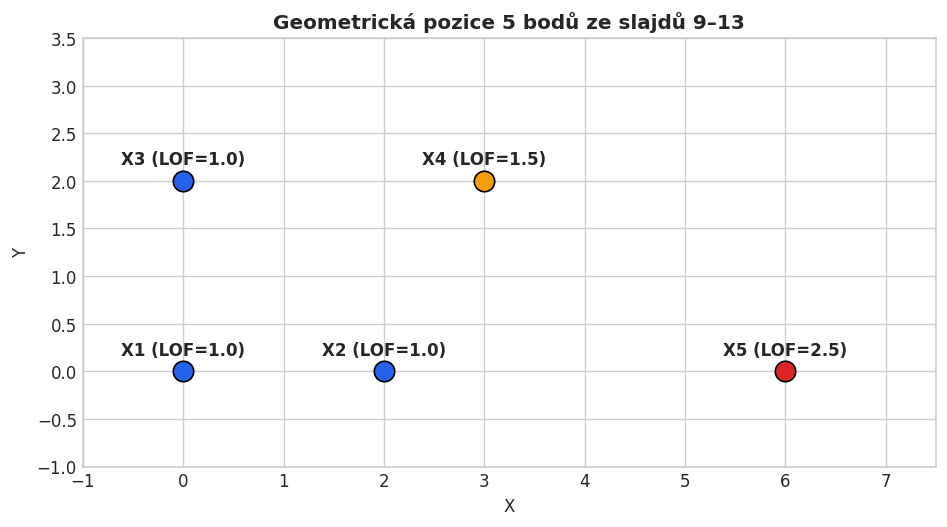

In [3]:
# 5 bodů z výukové ukázky ze slajdů
toy_points = pd.DataFrame([
    {'Bod': 'X1', 'X': 0.0, 'Y': 0.0, 'k_dist (k=2)': 2.0, 'LRD': 0.5, 'LOF': 1.0, 'Hodnocení': 'Normální bod'},
    {'Bod': 'X2', 'X': 2.0, 'Y': 0.0, 'k_dist (k=2)': 2.0, 'LRD': 0.5, 'LOF': 1.0, 'Hodnocení': 'Normální bod'},
    {'Bod': 'X3', 'X': 0.0, 'Y': 2.0, 'k_dist (k=2)': 2.0, 'LRD': 0.5, 'LOF': 1.0, 'Hodnocení': 'Normální bod'},
    {'Bod': 'X4', 'X': 3.0, 'Y': 2.0, 'k_dist (k=2)': 3.0, 'LRD': 0.3333, 'LOF': 1.5, 'Hodnocení': 'Mírná anomálie'},
    {'Bod': 'X5', 'X': 6.0, 'Y': 0.0, 'k_dist (k=2)': 6.0, 'LRD': 0.1667, 'LOF': 2.5, 'Hodnocení': 'Silná anomálie'}
])
print('Krokový ruční výpočet ze slajdů kurzu:')
print(toy_points.to_string(index=False))

# Vizualizace 5 bodů
plt.figure(figsize=(8, 4.5))
colors_toy = {'Normální bod': '#2563eb', 'Mírná anomálie': '#f59e0b', 'Silná anomálie': '#dc2626'}
for _, row in toy_points.iterrows():
    plt.scatter(row['X'], row['Y'], s=150, color=colors_toy[row['Hodnocení']], edgecolors='k', zorder=5)
    plt.annotate(f"{row['Bod']} (LOF={row['LOF']})", (row['X'], row['Y']), textcoords='offset points', xytext=(0, 10), ha='center', fontweight='bold')

plt.title('Geometrická pozice 5 bodů ze slajdů 9–13', fontsize=12, fontweight='bold')
plt.xlabel('X')
plt.ylabel('Y')
plt.xlim(-1, 7.5)
plt.ylim(-1, 3.5)
plt.tight_layout()
plt.show()

## 3. Aplikace na datasetu kurzu blobs_dataset.csv (1 000 bodů)

Natrénujeme LOF na standardizovaném datasetu `blobs_dataset.csv` a vykreslíme bublinový graf, kde poloměr odpovídá stupni anomality.

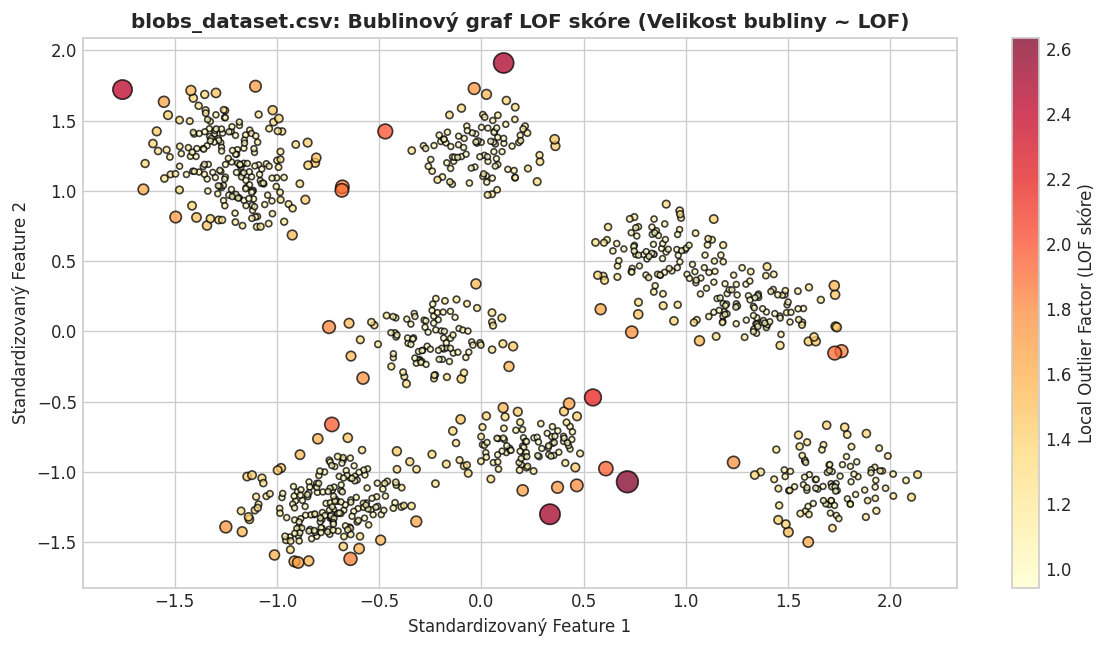

In [4]:
candidates = [
    Path('data/Downloadable materials for Session 3/blobs_dataset.csv'),
    Path('../data/Downloadable materials for Session 3/blobs_dataset.csv')
]
data_path = None
for p in candidates:
    if p.exists():
        data_path = p
        break

df_blobs = pd.read_csv(data_path)
scaler = StandardScaler()
X_blobs_s = scaler.fit_transform(df_blobs[['feature_1', 'feature_2']])

lof_blobs = LocalOutlierFactor(n_neighbors=20, contamination=0.03)
blobs_labels = lof_blobs.fit_predict(X_blobs_s)
blobs_lof_scores = -lof_blobs.negative_outlier_factor_

plt.figure(figsize=(10, 5.5))
radius = 12 + 65 * np.maximum(0, blobs_lof_scores - 1.0) ** 1.8
sc = plt.scatter(X_blobs_s[:, 0], X_blobs_s[:, 1], s=radius, c=blobs_lof_scores, cmap='YlOrRd', edgecolors='k', alpha=0.75)
cbar = plt.colorbar(sc)
cbar.set_label('Local Outlier Factor (LOF skóre)')
plt.title('blobs_dataset.csv: Bublinový graf LOF skóre (Velikost bubliny ~ LOF)', fontsize=12, fontweight='bold')
plt.xlabel('Standardizovaný Feature 1')
plt.ylabel('Standardizovaný Feature 2')
plt.tight_layout()
plt.show()

## 4. Srovnání metodik: LOF vs. Isolation Forest

Porovnáme predikce hustotního LOF a stromového ansámblu Isolation Forest na shodné $3\,\%$ kontaminaci.

In [5]:
iforest = IsolationForest(contamination=0.03, random_state=42)
if_labels = iforest.fit_predict(X_blobs_s)

ct = pd.crosstab(
    pd.Series(blobs_labels, name='LOF'),
    pd.Series(if_labels, name='Isolation Forest'),
    rownames=['LOF (-1=Outlier)'],
    colnames=['iForest (-1=Outlier)']
)
print('Křížová tabulka shody LOF vs. Isolation Forest:')
print(ct)
both = np.sum((blobs_labels == -1) & (if_labels == -1))
print(f'Shoda na anomáliích: {both} z 30 bodů ({both/30*100:.1f} %)')

Křížová tabulka shody LOF vs. Isolation Forest:
iForest (-1=Outlier)  -1    1
LOF (-1=Outlier)             
-1                     9   21
 1                    21  949
Shoda na anomáliích: 9 z 30 bodů (30.0 %)


## 5. Experiment: Schopnost LOF řešit proměnlivou hustotu (Varying Density)

Demonstrace na syntetickém scénáři se dvěma shluky o různé hustotě ($C_1$ hustý, $C_2$ řídký) a lokální anomálií u $C_1$.

C:\Users\xeen\AppData\Local\Temp\ipykernel_34228\731372660.py:29: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\xeen\AppData\Local\Temp\ipykernel_34228\731372660.py:29: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\xeen\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\xeen\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


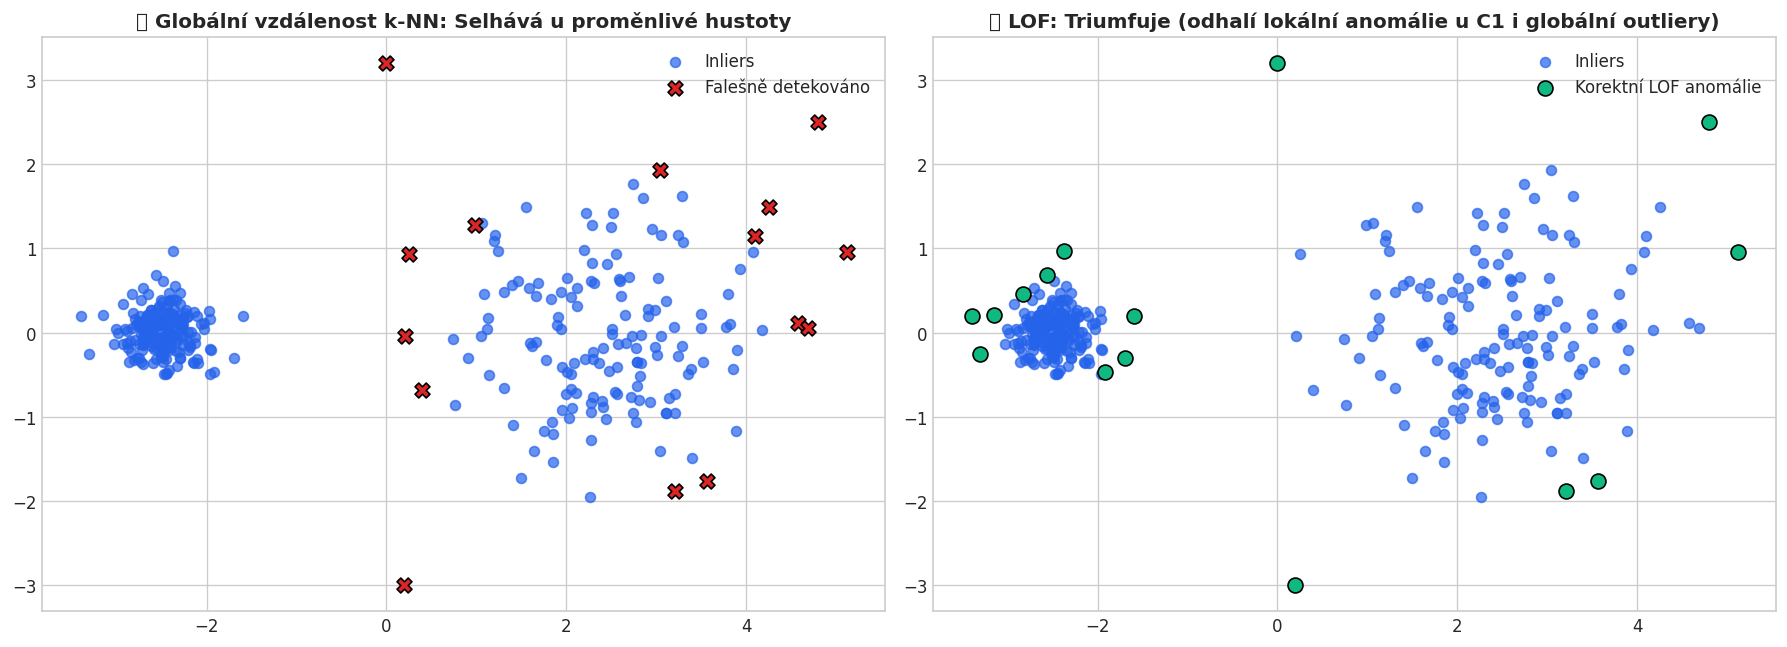

In [6]:
np.random.seed(42)
c1 = np.random.normal(loc=[-2.5, 0.0], scale=0.25, size=(200, 2))
c2 = np.random.normal(loc=[2.5, 0.0], scale=0.85, size=(150, 2))
loc_anom = np.array([[-1.6, 0.2], [-1.7, -0.3], [-3.4, 0.2]])
glob_anom = np.array([[0.0, 3.2], [0.2, -3.0], [4.8, 2.5]])
X_bench = np.vstack([c1, c2, loc_anom, glob_anom])

# Globální k-NN vzdálenost
knn = NearestNeighbors(n_neighbors=25).fit(X_bench)
dists, _ = knn.kneighbors(X_bench)
glob_dists = dists[:, -1]
glob_outliers = glob_dists >= np.percentile(glob_dists, 96)

# LOF s lokální hustotou
lof_bench = LocalOutlierFactor(n_neighbors=25, contamination=0.04)
lof_bench_labels = lof_bench.fit_predict(X_bench)
lof_outliers = (lof_bench_labels == -1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
ax1.scatter(X_bench[~glob_outliers, 0], X_bench[~glob_outliers, 1], c='#2563eb', s=35, alpha=0.7, label='Inliers')
ax1.scatter(X_bench[glob_outliers, 0], X_bench[glob_outliers, 1], c='#dc2626', s=80, marker='X', edgecolors='k', label='Falešně detekováno')
ax1.set_title('❌ Globální vzdálenost k-NN: Selhává u proměnlivé hustoty', fontweight='bold')
ax1.legend()

ax2.scatter(X_bench[~lof_outliers, 0], X_bench[~lof_outliers, 1], c='#2563eb', s=35, alpha=0.7, label='Inliers')
ax2.scatter(X_bench[lof_outliers, 0], X_bench[lof_outliers, 1], c='#10b981', s=80, marker='o', edgecolors='k', label='Korektní LOF anomálie')
ax2.set_title('✅ LOF: Triumfuje (odhalí lokální anomálie u C1 i globální outliery)', fontweight='bold')
ax2.legend()
plt.tight_layout()
plt.show()

## 6. Režim Novelty Detection (`novelty=True`) pro produkční inferenci

Pokud model trénujeme s `novelty=True`, můžeme volat metody `predict()` a `decision_function()` na nových příchozích datech v reálném čase.

In [7]:
lof_novelty = LocalOutlierFactor(n_neighbors=20, novelty=True)
lof_novelty.fit(X_slide)

X_incoming = np.array([
    [-2.0, 8.0],   # Běžný bod uvnitř prvního shluku
    [12.0, -10.0]  # Extrémní nová anomálie
])

incoming_preds = lof_novelty.predict(X_incoming)
incoming_scores = lof_novelty.decision_function(X_incoming)

for i, (pred, score) in enumerate(zip(incoming_preds, incoming_scores)):
    stav = '✅ Normální bod (Inlier)' if pred == 1 else '🚨 Detekována Nová Anomálie (Outlier)'
    print(f'Vzorek {i+1} {X_incoming[i]}: {stav} | Decision Function: {score:.4f}')

Vzorek 1 [-2.  8.]: ✅ Normální bod (Inlier) | Decision Function: 0.5264
Vzorek 2 [ 12. -10.]: 🚨 Detekována Nová Anomálie (Outlier) | Decision Function: -5.3516
